# NYC Housing × Transportation — Milestone 1

## 0. Project Overview & Datasets

**Housing:** Housing Maintenance Code Complaints and Problems (HPD)
https://data.cityofnewyork.us/d/ygpa-z7cr

**Transportation:** Serious Injury Response, Tracking & Analysis Program (SIRTA, NYC DOT)
https://data.cityofnewyork.us/d/xeqp-qz8h

**Integration plan:** ZIP code × year (2022–2025); borough × month for seasonal analysis.

## 1. Setup & Imports

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from urllib.parse import urlencode
from scipy.spatial import cKDTree
%matplotlib inline

## 2. Data Loading

### 2.0 Dataset links and local files

In [19]:
# Dataset IDs found in each dataset's NYC Open Data URL
housing_id = 'ygpa-z7cr'     # HPD Housing Maintenance Code Complaints and Problems
transport_id = 'xeqp-qz8h'   # SIRTA - Serious Injury Crashes

base_url = 'https://data.cityofnewyork.us/api/views/{}/rows.csv?accessType=download'
api_url = 'https://data.cityofnewyork.us/resource/{}.csv'

# Local copies of the raw data, so we only download once (data/raw is not pushed to GitHub)
os.makedirs('../data/raw', exist_ok=True)
sirta_file = '../data/raw/sirta_raw.pkl'
hpd_file = '../data/raw/hpd_2022_2025.pkl'

### 2.1 SIRTA (transportation)

In [20]:
# SIRTA is small (~13k rows), so we load the full dataset (Listing 1)
if os.path.exists(sirta_file):
    df_transport = pd.read_pickle(sirta_file)
else:
    df_transport = pd.read_csv(base_url.format(transport_id), low_memory=False)
    df_transport.to_pickle(sirta_file)

df_transport.head()

,Collision ID,Crash Date,Crash Time,Crash Police Precinct,Crash Borough,Total Non-Severe Injuries,Total Severe Injuries,Total Fatalities,Latitude,Longitude,...,Highway Reference Marker,ZipCode,Similar Fatalities & Severe Injuries (3Y Lookback),Similar Fatalities & All Injuries (3Y Lookback),Community Board,Council District,Building Identification Number (BIN),Borough Block Lot (BBL),Census Tract (2020),Neighborhood Tabulation Area (NTA) (2020)
0,4492364.0,01/01/2022,01:28,46.0,Bronx,1.0,1.0,0.0,40.858707,-73.90370,...,NaN,NaN,0.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN
1,4491159.0,01/01/2022,04:33,46.0,Bronx,0.0,1.0,0.0,NaN,NaN,...,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
2,4491487.0,01/01/2022,05:55,47.0,Bronx,0.0,1.0,0.0,40.871550,-73.86428,...,NaN,NaN,0.0,0.0,212.0,12.0,2056281.0,2.045980e+09,372.0,BX1201
3,4491223.0,01/01/2022,10:42,43.0,Bronx,0.0,1.0,0.0,40.823673,-73.87233,...,907HX1M11001,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
4,4491418.0,01/01/2022,20:55,49.0,Bronx,0.0,1.0,0.0,40.863945,-73.86452,...,NaN,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN


SIRTA is loaded in full: 13,754 crashes × 23 columns (January 2022 to mid-2026).

### 2.2 HPD (housing)

In [21]:
# HPD has ~14M rows, so before loading we count the rows per year to choose a safe filter
params = {
    '$select': 'date_extract_y(received_date) AS year, count(*) AS n_rows',
    '$where': "received_date >= '2022-01-01T00:00:00'",
    '$group': 'year',
    '$order': 'year'
}
hpd_counts = pd.read_csv(api_url.format(housing_id) + '?' + urlencode(params))
hpd_counts

,year,n_rows
0,2022,733471
1,2023,747466
2,2024,823169
3,2025,856280
4,2026,797484


In [22]:
# Columns we need from HPD (time, location, complaint categories and status)
hpd_columns = ['received_date', 'problem_id', 'complaint_id', 'borough', 'post_code',
               'latitude', 'longitude', 'community_board', 'nta', 'unit_type', 'space_type',
               'type', 'major_category', 'minor_category', 'complaint_status',
               'problem_status', 'problem_duplicate_flag']

if os.path.exists(hpd_file):
    df_housing = pd.read_pickle(hpd_file)
else:
    # Load one year at a time (Listing 2), each year has less than 1M rows
    yearly_data = []
    for year in [2022, 2023, 2024, 2025]:
        params = {
            '$select': ', '.join(hpd_columns),
            '$where': f"received_date >= '{year}-01-01T00:00:00' AND received_date < '{year + 1}-01-01T00:00:00'",
            '$limit': 1000000,
            '$order': ':id'    # stable order so the download is repeatable
        }
        df_year = pd.read_csv(api_url.format(housing_id) + '?' + urlencode(params),
                              low_memory=False, dtype={'post_code': str})
        yearly_data.append(df_year)
    df_housing = pd.concat(yearly_data, ignore_index=True)
    df_housing.to_pickle(hpd_file)

df_housing.head()

,received_date,problem_id,complaint_id,borough,post_code,latitude,longitude,community_board,nta,unit_type,space_type,type,major_category,minor_category,complaint_status,problem_status,problem_duplicate_flag
0,2022-01-16T00:54:39.000,22273633,11054566,MANHATTAN,10029,40.793701,-73.941804,11,East Harlem (North),APARTMENT,BEDROOM,EMERGENCY,HEAT/HOT WATER,APARTMENT ONLY,CLOSE,CLOSE,N
1,2022-01-16T00:54:39.000,22273634,11054566,MANHATTAN,10029,40.793701,-73.941804,11,East Harlem (North),APARTMENT,BEDROOM,EMERGENCY,DOOR/WINDOW,WINDOW PANE,CLOSE,CLOSE,N
2,2022-01-23T22:05:21.000,22307373,11078555,MANHATTAN,10044,40.757748,-73.953581,8,Upper East Side-Lenox Hill-Roosevelt Island,APARTMENT,BATHROOM,NON EMERGENCY,WATER LEAK,SLOW LEAK,CLOSE,CLOSE,N
3,2022-02-04T13:40:22.000,22359869,11107818,MANHATTAN,10032,40.837506,-73.945343,12,Washington Heights (South),APARTMENT,BATHROOM,NON EMERGENCY,WATER LEAK,SLOW LEAK,CLOSE,CLOSE,N
4,2022-02-04T13:40:22.000,22359870,11107818,MANHATTAN,10032,40.837506,-73.945343,12,Washington Heights (South),APARTMENT,BATHROOM,EMERGENCY,PLUMBING,BASIN/SINK,CLOSE,CLOSE,N


**Sample:** HPD has ~14M rows (2001–present), so we load only 2022–2025 (the full years that overlap with SIRTA; 2026 is incomplete) and 17 of its 33 columns, one year at a time because the API returns at most 1,000,000 rows per request. Result: 3,160,386 problems.

## 3. Exploratory Data Analysis (EDA)

### 3.1 Structure check

In [6]:
# Number of rows & columns
print(df_transport.shape)
print(df_housing.shape)

(13754, 23)
(3160386, 17)


In [7]:
# Columns, data types and non-null counts of SIRTA
df_transport.info()

<class 'pandas.DataFrame'>
RangeIndex: 13754 entries, 0 to 13753
Data columns (total 23 columns):
 #   Column                                              Non-Null Count  Dtype  
---  ------                                              --------------  -----  
 0   Collision ID                                        13310 non-null  float64
 1   Crash Date                                          13310 non-null  str    
 2   Crash Time                                          13310 non-null  str    
 3   Crash Police Precinct                               13310 non-null  float64
 4   Crash Borough                                       13255 non-null  str    
 5   Total Non-Severe Injuries                           13310 non-null  float64
 6   Total Severe Injuries                               13310 non-null  float64
 7   Total Fatalities                                    13310 non-null  float64
 8   Latitude                                            10868 non-null  float64
 9   Longit

In [8]:
# Columns, data types and non-null counts of HPD
df_housing.info()

<class 'pandas.DataFrame'>
RangeIndex: 3160386 entries, 0 to 3160385
Data columns (total 17 columns):
 #   Column                  Dtype   
---  ------                  -----   
 0   received_date           str     
 1   problem_id              int64   
 2   complaint_id            int64   
 3   borough                 category
 4   post_code               str     
 5   latitude                float64 
 6   longitude               float64 
 7   community_board         int64   
 8   nta                     str     
 9   unit_type               str     
 10  space_type              category
 11  type                    category
 12  major_category          str     
 13  minor_category          str     
 14  complaint_status        category
 15  problem_status          category
 16  problem_duplicate_flag  category
dtypes: category(6), float64(2), int64(3), str(6)
memory usage: 283.3 MB


In [9]:
# Number and percentage of missing values per column in SIRTA
null_values = df_transport.isnull().sum()
percent = (null_values / len(df_transport)) * 100
pd.DataFrame({'missing': null_values, 'percent': percent.round(2)}).sort_values('percent', ascending=False)

,missing,percent
Highway Reference Marker,12702,92.35
Address,11177,81.26
Building Identification Number (BIN),10967,79.74
Borough Block Lot (BBL),10967,79.74
Census Tract (2020),9886,71.88
Neighborhood Tabulation Area (NTA) (2020),9886,71.88
Council District,9883,71.86
Community Board,9883,71.86
ZipCode,5682,41.31
Cross Street,5642,41.02


In [10]:
# Number and percentage of missing values per column in HPD
null_values = df_housing.isnull().sum()
percent = (null_values / len(df_housing)) * 100
pd.DataFrame({'missing': null_values, 'percent': percent.round(2)}).sort_values('percent', ascending=False)

,missing,percent
post_code,3287,0.10
longitude,663,0.02
nta,663,0.02
latitude,663,0.02
received_date,0,0.00
borough,0,0.00
complaint_id,0,0.00
problem_id,0,0.00
community_board,0,0.00
unit_type,0,0.00


**Result:** SIRTA has 444 completely empty rows, ZIP is missing in 41% of crashes (coordinates in only 21%) and 8 columns are 70–92% empty. HPD is almost complete (post code missing in 0.1%). Dates are stored as text in both datasets.

### 3.2 Descriptive statistics

In [11]:
# Descriptive statistics of the numeric columns in SIRTA
df_transport.describe()

,Collision ID,Crash Police Precinct,Total Non-Severe Injuries,Total Severe Injuries,Total Fatalities,Latitude,Longitude,ZipCode,Similar Fatalities & Severe Injuries (3Y Lookback),Similar Fatalities & All Injuries (3Y Lookback),Community Board,Council District,Building Identification Number (BIN),Borough Block Lot (BBL),Census Tract (2020)
count,1.331000e+04,13310.000000,13310.000000,13310.000000,13310.000000,10868.000000,10868.000000,8072.000000,11917.000000,13310.000000,3871.000000,3871.000000,2.787000e+03,2.787000e+03,3868.000000
mean,7.271533e+06,67.837866,0.270473,1.011495,0.082795,40.730641,-73.921537,10819.590312,0.095494,1.544328,274.361664,24.297856,2.743007e+06,2.654365e+09,19862.728800
std,1.128930e+07,34.683947,0.836031,0.451514,0.294304,0.083378,0.081929,543.749751,0.421729,5.857394,117.942477,15.207332,1.222342e+06,1.176180e+09,30729.779508
min,2.126022e+06,1.000000,0.000000,0.000000,0.000000,40.499672,-74.248570,10000.000000,0.000000,0.000000,101.000000,1.000000,1.000000e+06,1.000020e+09,2.000000
25%,4.612503e+06,42.000000,0.000000,1.000000,0.000000,40.667854,-73.968790,10312.000000,0.000000,0.000000,202.000000,11.000000,2.006037e+06,2.025824e+09,248.000000
50%,4.718838e+06,68.000000,0.000000,1.000000,0.000000,40.726710,-73.923693,11204.000000,0.000000,0.000000,305.000000,23.000000,3.047144e+06,3.014678e+09,1903.000000
75%,4.814223e+06,104.000000,0.000000,1.000000,0.000000,40.800663,-73.874742,11235.000000,0.000000,1.000000,401.000000,38.000000,3.399010e+06,3.080965e+09,27326.750000
max,1.213261e+08,123.000000,19.000000,7.000000,5.000000,40.912468,-73.700600,11694.000000,9.000000,296.000000,503.000000,51.000000,5.174401e+06,5.200430e+09,161700.000000


In [12]:
# Descriptive statistics of the numeric columns in HPD
df_housing.describe()

,problem_id,complaint_id,latitude,longitude,community_board
count,3.160386e+06,3.160386e+06,3.159723e+06,3.159723e+06,3.160386e+06
mean,2.513780e+07,1.271077e+07,4.076332e+01,-7.391846e+01,7.904607e+00
std,1.687747e+06,9.479360e+05,8.924502e-02,5.666499e-02,4.354839e+00
min,2.218926e+07,1.100298e+07,4.049982e+01,-7.425162e+01,0.000000e+00
25%,2.365345e+07,1.189283e+07,4.067654e+01,-7.395051e+01,4.000000e+00
50%,2.511295e+07,1.271148e+07,4.079427e+01,-7.392074e+01,8.000000e+00
75%,2.660138e+07,1.353334e+07,4.084159e+01,-7.388925e+01,1.100000e+01
max,2.803712e+07,1.435741e+07,4.091229e+01,-7.370074e+01,3.050000e+02


In [13]:
# Number of crashes per borough
df_transport['Crash Borough'].value_counts()

Crash Borough
Brooklyn         3954
Queens           3282
Manhattan        2733
Bronx            2617
Staten Island     669
Name: count, dtype: int64

In [14]:
# Number of problems per borough, complaint type and major category
print(df_housing['borough'].value_counts())
print(df_housing['type'].value_counts())
print(df_housing['major_category'].value_counts())

borough
BRONX            1103496
BROOKLYN          916253
MANHATTAN         684423
QUEENS            398702
STATEN ISLAND      57512
Name: count, dtype: int64
type
EMERGENCY              1933466
NON EMERGENCY          1108009
IMMEDIATE EMERGENCY     118911
Name: count, dtype: int64
major_category
HEAT/HOT WATER          1087433
UNSANITARY CONDITION     520732
PLUMBING                 297163
PAINT/PLASTER            278048
DOOR/WINDOW              216256
WATER LEAK               174831
GENERAL                  138127
ELECTRIC                 127439
FLOORING/STAIRS          121472
APPLIANCE                 95670
SAFETY                    81540
OUTSIDE BUILDING           7409
ELEVATOR                   7335
LINE OF TRAVEL             6931
Name: count, dtype: int64


**Result:** SIRTA's ZIP is stored as a number and includes invalid values (e.g. 10000), and injuries are very skewed (median 0, max 19). HPD's `community_board` has invalid values (0 and above 18). Boroughs are written differently in the two datasets (`Brooklyn` vs `BROOKLYN`).

### 3.3 Initial plots

#### Crashes vs complaints by borough

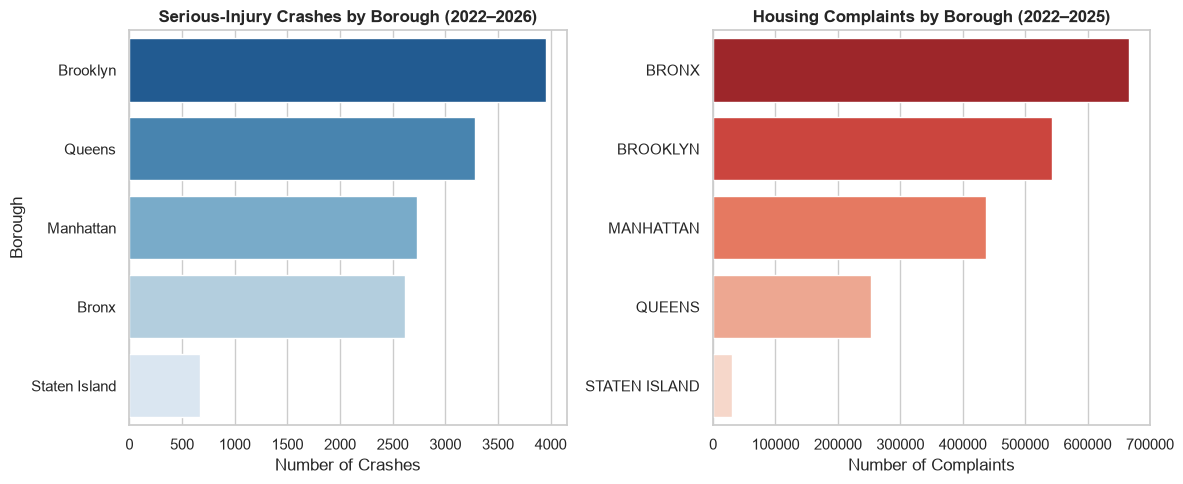

In [15]:
# One complaint can contain several problems, so we count unique complaint IDs
sns.set_theme(style="whitegrid", palette="muted")

crash_boro = df_transport['Crash Borough'].value_counts()
complaint_boro = df_housing.groupby('borough')['complaint_id'].nunique().sort_values(ascending=False)

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(12, 5))
sns.barplot(x=crash_boro.values, y=crash_boro.index, hue=crash_boro.index,
            dodge=False, legend=False, palette="Blues_r", ax=ax[0])
ax[0].set_title("Serious-Injury Crashes by Borough (2022–2026)", fontsize=12, weight="bold")
ax[0].set_xlabel("Number of Crashes")
ax[0].set_ylabel("Borough")

sns.barplot(x=complaint_boro.values, y=complaint_boro.index, hue=complaint_boro.index,
            dodge=False, legend=False, palette="Reds_r", ax=ax[1])
ax[1].set_title("Housing Complaints by Borough (2022–2025)", fontsize=12, weight="bold")
ax[1].set_xlabel("Number of Complaints")
ax[1].set_ylabel("")
plt.tight_layout()
plt.show()

Brooklyn has the most serious crashes, while the Bronx has the most housing complaints. Queens ranks 2nd for crashes but only 4th for complaints.

#### Top housing problem categories

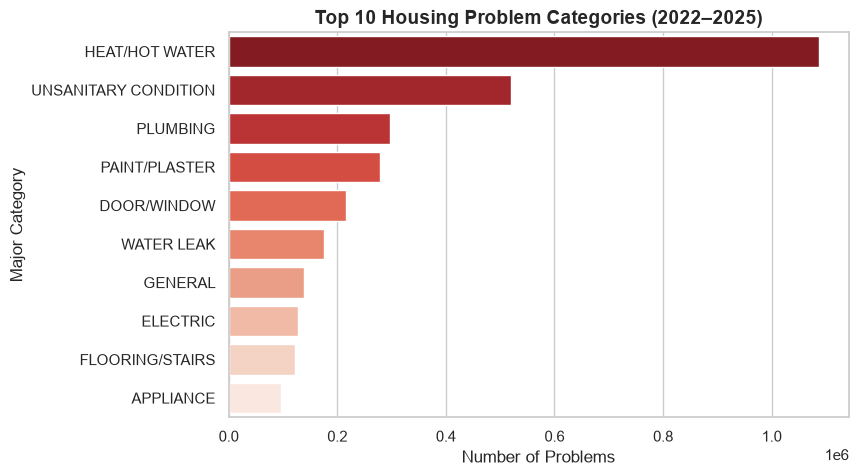

In [16]:
# Top 10 housing problem categories
top_categories = df_housing['major_category'].value_counts().head(10)

plt.figure(figsize=(8, 5))
sns.barplot(x=top_categories.values, y=top_categories.index, hue=top_categories.index,
            dodge=False, legend=False, palette="Reds_r")
plt.title("Top 10 Housing Problem Categories (2022–2025)", fontsize=14, weight="bold")
plt.xlabel("Number of Problems")
plt.ylabel("Major Category")
plt.show()

Heat/hot water problems (~1.1M) are about twice as common as the next category, unsanitary conditions.

#### Injury distributions (outliers)

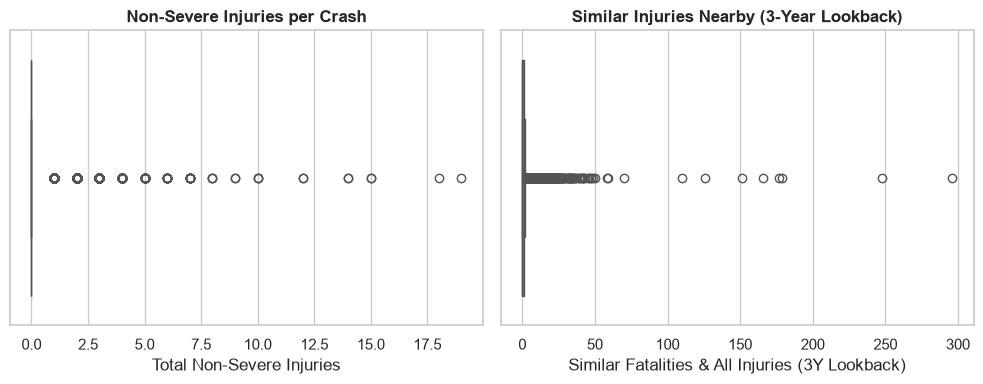

In [17]:
# Box plots to check the injury columns for outliers
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))
sns.boxplot(x=df_transport['Total Non-Severe Injuries'], ax=ax[0])
ax[0].set_title("Non-Severe Injuries per Crash", fontsize=12, weight="bold")
sns.boxplot(x=df_transport['Similar Fatalities & All Injuries (3Y Lookback)'], ax=ax[1])
ax[1].set_title("Similar Injuries Nearby (3-Year Lookback)", fontsize=12, weight="bold")
plt.tight_layout()
plt.show()

Most crashes have 0 non-severe injuries. The high values are real multi-casualty crashes (e.g. bus crashes), so they are kept.

#### Monthly trend of both datasets

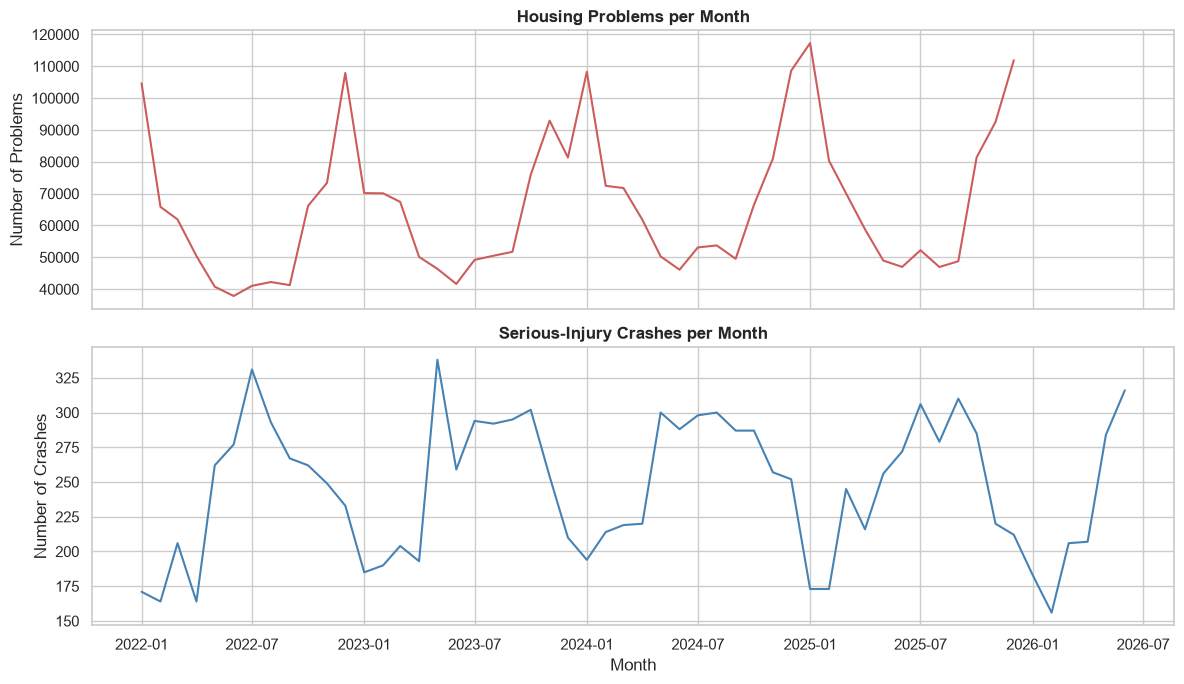

In [18]:
# Count records per month (dates are converted only for this plot; the real conversion is done in cleaning)
crash_months = pd.to_datetime(df_transport['Crash Date'], format='%m/%d/%Y').dt.to_period('M').value_counts().sort_index()
problem_months = pd.to_datetime(df_housing['received_date']).dt.to_period('M').value_counts().sort_index()

# Two charts on top of each other, because housing problems are ~1000x more frequent than crashes
fig, ax = plt.subplots(nrows=2, ncols=1, figsize=(12, 7), sharex=True)
ax[0].plot(problem_months.index.to_timestamp(), problem_months.values, color="indianred")
ax[0].set_title("Housing Problems per Month", fontsize=12, weight="bold")
ax[0].set_ylabel("Number of Problems")
ax[1].plot(crash_months.index.to_timestamp(), crash_months.values, color="steelblue")
ax[1].set_title("Serious-Injury Crashes per Month", fontsize=12, weight="bold")
ax[1].set_ylabel("Number of Crashes")
ax[1].set_xlabel("Month")
plt.tight_layout()
plt.show()

Housing problems peak every winter (heating season), while serious crashes peak every summer.

## 4. Pre-Integration Cleaning

### 4.1 Cleaning SIRTA

In [23]:
# Drop the empty rows (no Collision ID and no Crash Date)
print(df_transport.shape)
df_transport = df_transport.dropna(subset=['Collision ID', 'Crash Date'])
print(df_transport.shape)

(13754, 23)
(13310, 23)


Dropped the 444 empty rows (no Collision ID or date), since there is nothing to fill them from: 13,754 → 13,310 rows.

In [24]:
# Drop the columns that are mostly empty
sparse_columns = ['Highway Reference Marker', 'Address', 'Building Identification Number (BIN)',
                  'Borough Block Lot (BBL)', 'Census Tract (2020)',
                  'Neighborhood Tabulation Area (NTA) (2020)', 'Council District', 'Community Board']
df_transport = df_transport.drop(columns=sparse_columns)
df_transport.shape

(13310, 15)

Dropped the 8 columns that are 70–92% empty and not needed for our research questions: 23 → 15 columns.

In [25]:
# Rename columns to lowercase_with_underscores (same style as HPD)
df_transport = df_transport.rename(columns={
    'Collision ID': 'collision_id',
    'Crash Date': 'crash_date',
    'Crash Time': 'crash_time',
    'Crash Police Precinct': 'police_precinct',
    'Crash Borough': 'borough',
    'Total Non-Severe Injuries': 'non_severe_injuries',
    'Total Severe Injuries': 'severe_injuries',
    'Total Fatalities': 'fatalities',
    'Latitude': 'latitude',
    'Longitude': 'longitude',
    'On Street': 'on_street',
    'Cross Street': 'cross_street',
    'ZipCode': 'zip_code',
    'Similar Fatalities & Severe Injuries (3Y Lookback)': 'similar_severe_3y',
    'Similar Fatalities & All Injuries (3Y Lookback)': 'similar_all_3y'
})

# Check the remaining missing values
df_transport.isnull().sum()

collision_id              0
crash_date                0
crash_time                0
police_precinct           0
borough                  55
non_severe_injuries       0
severe_injuries           0
fatalities                0
latitude               2442
longitude              2442
on_street              2592
cross_street           5198
zip_code               5238
similar_severe_3y      1393
similar_all_3y            0
dtype: int64

Renamed the columns to lowercase_with_underscores to match HPD. Remaining gaps: borough (55), coordinates (2,442) and ZIP (5,238); `on_street`, `cross_street` and `similar_severe_3y` are not used in the analysis.

In [26]:
# Convert crash_date from text to datetime
df_transport['crash_date'] = pd.to_datetime(df_transport['crash_date'], format='%m/%d/%Y')

# Keep only 2022–2025 to match HPD
df_transport = df_transport[(df_transport['crash_date'] >= '2022-01-01') & (df_transport['crash_date'] < '2026-01-01')]
print(df_transport.shape)
print(df_transport['crash_date'].min(), df_transport['crash_date'].max())

(11958, 15)
2022-01-01 00:00:00 2025-12-30 00:00:00


Converted `crash_date` to datetime and kept only 2022–2025 to match HPD: 11,958 crashes remain.

In [27]:
# Fill the missing boroughs from the police precinct number
def precinct_to_borough(precinct):
    if precinct <= 34:
        return 'MANHATTAN'
    elif precinct <= 52:
        return 'BRONX'
    elif precinct <= 94:
        return 'BROOKLYN'
    elif precinct <= 115:
        return 'QUEENS'
    else:
        return 'STATEN ISLAND'

df_transport['borough'] = df_transport['borough'].fillna(df_transport['police_precinct'].apply(precinct_to_borough))

# Write boroughs in uppercase to match HPD
df_transport['borough'] = df_transport['borough'].str.upper()
df_transport['borough'].value_counts(dropna=False)

borough
BROOKLYN         3557
QUEENS           2974
MANHATTAN        2448
BRONX            2365
STATEN ISLAND     614
Name: count, dtype: int64

Filled the 55 missing boroughs from the police precinct (every precinct belongs to exactly one borough) and converted boroughs to uppercase to match HPD.

In [28]:
# Extract the hour of the crash from the text time (e.g. '20:55' -> 20)
df_transport['crash_hour'] = pd.to_datetime(df_transport['crash_time'], format='%H:%M').dt.hour
df_transport['crash_hour'].value_counts().sort_index()

crash_hour
0     580
1     318
2     280
3     275
4     298
5     240
6     334
7     344
8     477
9     411
10    420
11    450
12    455
13    590
14    652
15    687
16    671
17    765
18    757
19    668
20    614
21    646
22    539
23    487
Name: count, dtype: int64

Crashes peak at 5–6 pm. The spike at midnight (580) is likely crashes with an unknown time recorded as 00:00.

In [29]:
# Mark ZIPs outside the NYC range as missing
invalid_zip = (df_transport['zip_code'] < 10001) | (df_transport['zip_code'] > 11697)
print('Invalid ZIPs:', invalid_zip.sum())
df_transport.loc[invalid_zip, 'zip_code'] = np.nan

# Convert ZIP from number to 5-digit text (10312.0 -> '10312')
df_transport['zip_code'] = df_transport['zip_code'].astype('Int64').astype(str).replace('<NA>', np.nan)
df_transport['zip_code'].head()

Invalid ZIPs: 36


0    NaN
1    NaN
2    NaN
3    NaN
4    NaN
Name: zip_code, dtype: str

In [31]:
# Check that ZIPs are now 5-digit text and count how many are still missing
print(df_transport['zip_code'].dropna().head())
print('Missing ZIPs:', df_transport['zip_code'].isnull().sum())

2146    10467
2148    10451
2150    10456
2151    10455
2152    10462
Name: zip_code, dtype: str
Missing ZIPs: 4923


Set the 36 ZIPs outside the NYC range (10001–11697) to missing and converted ZIP from a number to 5-digit text, like HPD's `post_code`. 4,923 ZIPs are still missing (filled in 4.3).

In [30]:
# Check and remove duplicate crashes
print('Duplicate collision IDs:', df_transport['collision_id'].duplicated().sum())
df_transport = df_transport.drop_duplicates(subset='collision_id')
df_transport.shape

Duplicate collision IDs: 0


(11958, 16)

No duplicate collision IDs were found.

In [32]:
# Crashes with no severe injury and no fatality
not_serious = (df_transport['severe_injuries'] == 0) & (df_transport['fatalities'] == 0)
print('Crashes with no severe injury or fatality:', not_serious.sum())

Crashes with no severe injury or fatality: 0


Every crash has at least one severe injury or fatality, as expected for SIRTA (0 violations).

In [33]:
# IQR outlier check on non-severe injuries
Q1 = df_transport['non_severe_injuries'].quantile(0.25)
Q3 = df_transport['non_severe_injuries'].quantile(0.75)
iqr = Q3 - Q1
lower_limit = Q1 - 1.5 * iqr
upper_limit = Q3 + 1.5 * iqr
outliers = df_transport[(df_transport['non_severe_injuries'] < lower_limit) | (df_transport['non_severe_injuries'] > upper_limit)]
print('Upper limit:', upper_limit)
print('Outliers:', len(outliers))
outliers['non_severe_injuries'].value_counts().sort_index()

Upper limit: 0.0
Outliers: 1971


non_severe_injuries
1.0     1316
2.0      366
3.0      152
4.0       67
5.0       35
6.0       10
7.0       11
8.0        3
9.0        2
10.0       3
12.0       1
14.0       2
15.0       2
19.0       1
Name: count, dtype: int64

The IQR rule flags all 1,971 crashes with at least one non-severe injury, because most crashes have 0 (Q1 = Q3 = 0). These are real values (max 19, e.g. a bus crash), so we keep them.

### 4.2 Cleaning HPD

In [34]:
# Convert received_date from text to datetime
df_housing['received_date'] = pd.to_datetime(df_housing['received_date'], format='%Y-%m-%dT%H:%M:%S.%f')
df_housing['year'] = df_housing['received_date'].dt.year
df_housing['month'] = df_housing['received_date'].dt.month
print(df_housing['received_date'].min(), df_housing['received_date'].max())
df_housing['year'].value_counts().sort_index()

2022-01-01 00:00:46 2025-12-31 23:59:41


year
2022    733471
2023    747466
2024    823169
2025    856280
Name: count, dtype: int64

Converted `received_date` to datetime and added `year` and `month`. All four years (2022–2025) are complete.

In [35]:
# Check the borough values
print(df_housing['borough'].value_counts())

# Mark post codes outside the NYC range as missing
post_code_number = pd.to_numeric(df_housing['post_code'], errors='coerce')
invalid_post_code = (post_code_number < 10001) | (post_code_number > 11697)
print('Invalid post codes:', invalid_post_code.sum())
df_housing.loc[invalid_post_code, 'post_code'] = np.nan
print('Missing post codes:', df_housing['post_code'].isnull().sum())

borough
BRONX            1103496
BROOKLYN          916253
MANHATTAN         684423
QUEENS            398702
STATEN ISLAND      57512
Name: count, dtype: int64
Invalid post codes: 199
Missing post codes: 3486


All 5 borough values are valid. 199 post codes outside the NYC range were set to missing, giving 3,486 missing post codes (0.11%).

In [36]:
# Drop problems without a valid post code (0.11% of rows)
df_housing = df_housing.dropna(subset=['post_code'])

# Drop the community_board column (invalid values and not needed)
df_housing = df_housing.drop(columns=['community_board'])
df_housing.shape

(3156900, 18)

Dropped the 3,486 problems without a post code (0.11%, too few to affect the results) and the `community_board` column (invalid values, not needed): 3,156,900 problems.

In [37]:
# Problems that HPD flagged as duplicates
print(df_housing['problem_duplicate_flag'].value_counts())
df_housing = df_housing[df_housing['problem_duplicate_flag'] == 'N']

# Check for repeated problem IDs
print('Duplicate problem IDs:', df_housing['problem_id'].duplicated().sum())
df_housing.shape

problem_duplicate_flag
N    2654702
Y     502198
Name: count, dtype: int64
Duplicate problem IDs: 0


(2654702, 18)

Removed 502,198 problems that HPD flagged as duplicates (16%). No repeated problem IDs remain: 2,654,702 problems.

### 4.3 Filling missing SIRTA ZIP codes
For crashes with coordinates but no ZIP, we use the ZIP of the nearest HPD address.

In [39]:
# Reference points: unique HPD locations that have coordinates and a ZIP
reference = df_housing.dropna(subset=['latitude', 'longitude'])
reference = reference[['latitude', 'longitude', 'post_code']].drop_duplicates(subset=['latitude', 'longitude'])

# At NYC's latitude, 1 degree of longitude is shorter than 1 degree of latitude, so we scale it
lon_scale = np.cos(np.radians(40.7))
tree = cKDTree(np.column_stack([reference['latitude'], reference['longitude'] * lon_scale]))

# For every crash with coordinates, find the nearest HPD location
has_coords = df_transport['latitude'].notna()
crash_points = np.column_stack([df_transport.loc[has_coords, 'latitude'],
                                df_transport.loc[has_coords, 'longitude'] * lon_scale])
distance, index = tree.query(crash_points)

df_transport.loc[has_coords, 'nearest_zip'] = reference['post_code'].values[index]
df_transport.loc[has_coords, 'nearest_distance_m'] = distance * 111000   # 1 degree ≈ 111 km
df_transport['nearest_distance_m'].describe()

count    9683.000000
mean       55.299861
std        90.679955
min         0.084153
25%        14.726743
50%        30.141272
75%        64.091550
max      1966.321880
Name: nearest_distance_m, dtype: float64

In [40]:
# Test: on crashes that already have a ZIP, how often does the nearest address give the same ZIP?
known = df_transport.dropna(subset=['zip_code', 'nearest_zip'])
accuracy = (known['zip_code'] == known['nearest_zip']).mean() * 100
print('Tested on', len(known), 'crashes')
print('Accuracy:', round(accuracy, 1), '%')

Tested on 5869 crashes
Accuracy: 93.2 %


The method was tested on 5,869 crashes that already had a ZIP: it gave the correct ZIP in 93.2% of cases, and half of the crashes are within 30 m of an HPD address.

In [41]:
# Fill missing ZIPs only when the nearest HPD address is within 500 m
close_enough = df_transport['nearest_distance_m'] <= 500
print('Missing ZIPs before:', df_transport['zip_code'].isnull().sum())
df_transport.loc[df_transport['zip_code'].isnull() & close_enough, 'zip_code'] = df_transport['nearest_zip']
print('Missing ZIPs after:', df_transport['zip_code'].isnull().sum())

# Remove the helper columns
df_transport = df_transport.drop(columns=['nearest_zip', 'nearest_distance_m'])
df_transport.shape

Missing ZIPs before: 4923
Missing ZIPs after: 1159


(11958, 16)

Missing ZIPs were filled only when the nearest HPD address is within 500 m (farther crashes are on highways or in parks): 4,923 → 1,159 missing. The remaining crashes have no coordinates; they are kept for borough-level analysis.

### 4.4 Validation of the cleaning

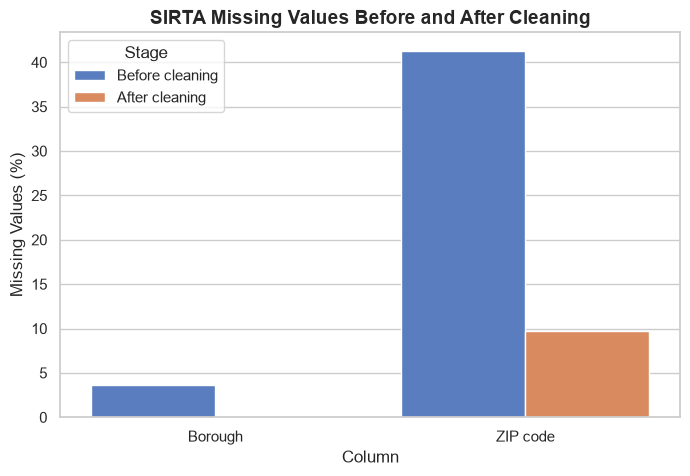

In [42]:
# Reload the raw SIRTA file to compare with the cleaned data
raw_transport = pd.read_pickle(sirta_file)

comparison = pd.DataFrame({
    'Column': ['Borough', 'Borough', 'ZIP code', 'ZIP code'],
    'Stage': ['Before cleaning', 'After cleaning', 'Before cleaning', 'After cleaning'],
    'Missing (%)': [raw_transport['Crash Borough'].isnull().mean() * 100,
                    df_transport['borough'].isnull().mean() * 100,
                    raw_transport['ZipCode'].isnull().mean() * 100,
                    df_transport['zip_code'].isnull().mean() * 100]
})

plt.figure(figsize=(8, 5))
sns.barplot(data=comparison, x='Column', y='Missing (%)', hue='Stage', palette="muted")
plt.title("SIRTA Missing Values Before and After Cleaning", fontsize=14, weight="bold")
plt.xlabel("Column")
plt.ylabel("Missing Values (%)")
plt.show()

Missing boroughs went from 3.6% to 0% and missing ZIPs from 41% to 9.7%.

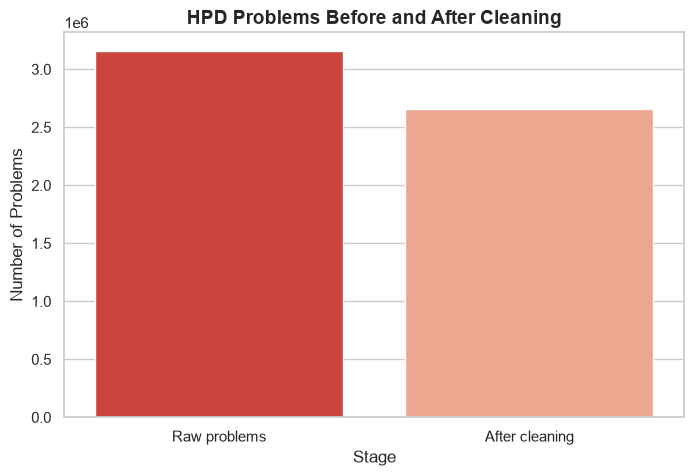

In [43]:
# Reload the raw HPD file to compare with the cleaned data
raw_housing = pd.read_pickle(hpd_file)

stages = pd.Series({'Raw problems': len(raw_housing),
                    'After cleaning': len(df_housing)})

plt.figure(figsize=(8, 5))
sns.barplot(x=stages.index, y=stages.values, hue=stages.index, dodge=False, legend=False, palette="Reds_r")
plt.title("HPD Problems Before and After Cleaning", fontsize=14, weight="bold")
plt.xlabel("Stage")
plt.ylabel("Number of Problems")
plt.show()

# Free memory, the raw copies are no longer needed
del raw_transport, raw_housing

HPD went from 3.16M to 2.65M problems, mainly from removing the duplicates.

## 5. Data Integration

### 5.1 Aggregation to ZIP code × year

In [44]:
# Count crashes, injuries and fatalities per ZIP and year
df_transport['year'] = df_transport['crash_date'].dt.year

crashes_zip_year = df_transport.dropna(subset=['zip_code']).groupby(['zip_code', 'year']).agg(
    crashes=('collision_id', 'count'),
    severe_injuries=('severe_injuries', 'sum'),
    fatalities=('fatalities', 'sum'),
    non_severe_injuries=('non_severe_injuries', 'sum')
).reset_index()

print(crashes_zip_year.shape)
crashes_zip_year.head()

(708, 6)


,zip_code,year,crashes,severe_injuries,fatalities,non_severe_injuries
0,10001,2022,15,17.0,0.0,2.0
1,10001,2023,26,24.0,2.0,9.0
2,10001,2024,22,25.0,0.0,18.0
3,10001,2025,18,17.0,1.0,3.0
4,10002,2022,26,31.0,2.0,5.0


In [45]:
# Mark emergency and heat/hot water problems so they can be counted
df_housing['is_emergency'] = df_housing['type'].isin(['EMERGENCY', 'IMMEDIATE EMERGENCY'])
df_housing['is_heat'] = df_housing['major_category'] == 'HEAT/HOT WATER'

# Count complaints and problems per ZIP and year (one complaint can contain several problems)
housing_zip_year = df_housing.groupby(['post_code', 'year']).agg(
    complaints=('complaint_id', 'nunique'),
    problems=('problem_id', 'count'),
    emergency_problems=('is_emergency', 'sum'),
    heat_problems=('is_heat', 'sum')
).reset_index().rename(columns={'post_code': 'zip_code'})

print(housing_zip_year.shape)
housing_zip_year.head()

(754, 6)


,zip_code,year,complaints,problems,emergency_problems,heat_problems
0,10001,2022,597,944,603,262
1,10001,2023,562,917,557,185
2,10001,2024,695,1240,689,255
3,10001,2025,696,1134,708,255
4,10002,2022,1876,2778,1884,949


Results: Both datasets are now counted per ZIP code and year: crashes, injuries and fatalities from SIRTA; unique complaints, problems, emergency problems and heat/hot water problems from HPD.

### 5.2 Joining the two datasets

In [46]:
# Outer join: keeps every ZIP-year from both tables, even if it appears in only one of them
df_merged = pd.merge(housing_zip_year, crashes_zip_year, on=['zip_code', 'year'], how='outer', indicator=True)

# Where each ZIP-year came from
print(df_merged.shape)
df_merged['_merge'].value_counts()

(766, 11)


_merge
both          696
left_only      58
right_only     12
Name: count, dtype: int64

In [47]:
# Add the borough of each ZIP (the borough that appears most often for that ZIP in HPD)
zip_borough = df_housing.groupby('post_code')['borough'].agg(lambda x: x.value_counts().index[0])
df_merged['borough'] = df_merged['zip_code'].map(zip_borough)
df_merged.head()

,zip_code,year,complaints,problems,emergency_problems,heat_problems,crashes,severe_injuries,fatalities,non_severe_injuries,_merge,borough
0,10001,2022,597.0,944.0,603.0,262.0,15.0,17.0,0.0,2.0,both,MANHATTAN
1,10001,2023,562.0,917.0,557.0,185.0,26.0,24.0,2.0,9.0,both,MANHATTAN
2,10001,2024,695.0,1240.0,689.0,255.0,22.0,25.0,0.0,18.0,both,MANHATTAN
3,10001,2025,696.0,1134.0,708.0,255.0,18.0,17.0,1.0,3.0,both,MANHATTAN
4,10002,2022,1876.0,2778.0,1884.0,949.0,26.0,31.0,2.0,5.0,both,MANHATTAN


### 5.3 Borough × month table (for seasonal patterns)

In [48]:
# Count crashes per borough, year and month
df_transport['month'] = df_transport['crash_date'].dt.month
crashes_borough_month = df_transport.groupby(['borough', 'year', 'month']).agg(
    crashes=('collision_id', 'count')
).reset_index()

# Count complaints and heat problems per borough, year and month
df_housing['borough'] = df_housing['borough'].astype(str)
housing_borough_month = df_housing.groupby(['borough', 'year', 'month']).agg(
    complaints=('complaint_id', 'nunique'),
    heat_problems=('is_heat', 'sum')
).reset_index()

# Join on borough, year and month
df_borough_month = pd.merge(housing_borough_month, crashes_borough_month,
                            on=['borough', 'year', 'month'], how='outer')
print(df_borough_month.shape)
df_borough_month.head()

(240, 6)


,borough,year,month,complaints,heat_problems,crashes
0,BRONX,2022,1,15920,10472,42
1,BRONX,2022,2,10396,5827,43
2,BRONX,2022,3,9942,5054,42
3,BRONX,2022,4,7573,3163,32
4,BRONX,2022,5,5814,1335,48


Results: Borough × month table: 5 boroughs × 48 months = 240 rows, with complaints, heat problems and crashes for each month. Together with the ZIP × year table, this lets us compare housing conditions and street safety in the same places and times, which neither dataset can show alone.

## 6. Post-Integration Cleaning

### 6.1 Missing values after the join

In [49]:
# Missing values created by the outer join
df_merged.isnull().sum()

zip_code                0
year                    0
complaints             12
problems               12
emergency_problems     12
heat_problems          12
crashes                58
severe_injuries        58
fatalities             58
non_severe_injuries    58
_merge                  0
borough                10
dtype: int64

In [50]:
# A ZIP-year missing from one dataset had no records there, so its counts are 0
count_columns = ['complaints', 'problems', 'emergency_problems', 'heat_problems',
                 'crashes', 'severe_injuries', 'fatalities', 'non_severe_injuries']
df_merged[count_columns] = df_merged[count_columns].fillna(0)

# The 12 SIRTA-only ZIPs have no borough from HPD, so we take it from SIRTA
sirta_zip_borough = df_transport.dropna(subset=['zip_code']).groupby('zip_code')['borough'].agg(lambda x: x.value_counts().index[0])
df_merged['borough'] = df_merged['borough'].fillna(df_merged['zip_code'].map(sirta_zip_borough))

df_merged.isnull().sum()

zip_code               0
year                   0
complaints             0
problems               0
emergency_problems     0
heat_problems          0
crashes                0
severe_injuries        0
fatalities             0
non_severe_injuries    0
_merge                 0
borough                0
dtype: int64

The outer join left 12 ZIP-years without housing counts, 58 without crash counts and 10 without a borough. A ZIP-year missing from one dataset had no records there, so its counts were set to 0 (a real value, not unknown); the 10 missing boroughs were taken from SIRTA. No missing values remain.

### 6.2 Redundant columns and data types

In [51]:
# Drop the helper column from the join, and store counts as whole numbers (they became decimals because of the NaN)
df_merged = df_merged.drop(columns=['_merge'])
df_merged[count_columns] = df_merged[count_columns].astype(int)

# Check the borough × month table too
print(df_borough_month.isnull().sum())
df_merged.dtypes

borough          0
year             0
month            0
complaints       0
heat_problems    0
crashes          0
dtype: int64


zip_code                 object
year                      int32
complaints                int64
problems                  int64
emergency_problems        int64
heat_problems             int64
crashes                   int64
severe_injuries           int64
fatalities                int64
non_severe_injuries       int64
borough                category
dtype: object

Dropped the `_merge` helper column and converted the counts back to whole numbers (they became decimals because of the NaN). The borough × month table has no missing values.

### 6.3 Saving the integrated data

In [52]:
# Store borough as text in both tables
df_merged['borough'] = df_merged['borough'].astype(str)

# Save the integrated tables for the analysis and the website (small files, pushed to GitHub)
os.makedirs('../data/processed', exist_ok=True)
df_merged.to_csv('../data/processed/zip_year.csv', index=False)
df_borough_month.to_csv('../data/processed/borough_month.csv', index=False)

# Save the cleaned crashes with coordinates for the website map
crash_points = df_transport.dropna(subset=['latitude', 'longitude'])[
    ['collision_id', 'crash_date', 'year', 'month', 'crash_hour', 'borough', 'zip_code',
     'latitude', 'longitude', 'severe_injuries', 'fatalities', 'non_severe_injuries']]
crash_points.to_csv('../data/processed/crash_points.csv', index=False)

print(df_merged.shape, df_borough_month.shape, crash_points.shape)

(766, 11) (240, 6) (9683, 12)


Saved three files in `data/processed/`: the integrated ZIP × year table (766 rows), the borough × month table (240 rows) and 9,683 cleaned crash locations for the website map.

## 7. Research Questions & Visualizations

## 8. Conclusions & Limitations

## 9. AI Prompt Log